# ESS·PV 최적화 파이프라인 — 1~3단계

`reference/parameters.md`의 물리·설비 파라미터로 DPNN 최적화에 필요한 입력을 준비한다.
이번에는 아래 표의 **1~3단계까지만** 진행(4단계 최적화 문제 정의부터는 이후 진행).

| 단계 | 할 일 | 목적 |
| --- | --- | --- |
| 1. 미래 부하 생성 | 기후 시나리오별 일별 전력수요를 15분 단위(96개)로 변환 | DPNN 입력 데이터 확보 |
| 2. PV 발전량 계산 | 일사량·기온과 가상 태양광 설비 사양으로 발전량 계산 | 공급 전력 산정 |
| 3. ESS 모델링 | 배터리 용량, 충방전 출력, 효율, SOC 제약 설정 | 물리적 제약 정의 |

부하 생성 모델은 `temperature_scenario_analysis.ipynb` 10절의 **다중재해모형**(res_multi) —
기온(스플라인+lag) 외에 그동안 유의하게 나타난 폭염주의보·폭염경보·열대야·대설주의보까지
전부 포함 — 을 그대로 재사용한다. 시나리오는 **present(실측)** + **SSP1-2.6/2-4.5/3-7.0/5-8.5
(2030년대·2050년대) 8종 future** 로 총 9개를 다룬다(SSP 델타는 동일 노트북 2절의 서울시
격자값 재사용, 캠퍼스 소재지 기준). future 시나리오에서는 기온만 delta-shift하고 습도·강수·캘린더·특보 플래그는
전부 실측값을 그대로 유지한다(= 2절과 동일한 PNAS식 delta-shift 원칙).

In [1]:
# 사전 준비: 데이터 로드 + 다중재해모형 재적합 (temperature_scenario_analysis.ipynb 10절과 동일 스펙)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

d = pd.read_csv("data/data_long.csv", parse_dates=["date"]).sort_values("date").reset_index(drop=True)
d["lnusage"] = np.log(d["usage_kwh"])
d["temp_lag1"] = d["temp_c"].shift(1)
d["temp_lag2"] = d["temp_c"].shift(2)
d["year"] = d["date"].dt.year
d["month"] = d["date"].dt.month
d["humidity_bin"] = pd.qcut(d["humidity_pct"], 6, labels=False)
est = d.dropna(subset=["lnusage", "temp_c", "temp_lag1", "temp_lag2", "humidity_pct", "precip_mm"]).copy()

formula = ("lnusage ~ cr(temp_c, df=7) + cr(temp_lag1, df=7) + cr(temp_lag2, df=7) "
           "+ C(humidity_bin) + precip_mm + holiday + vacation + exam_period "
           "+ C(day_of_week) + C(month) + C(year)")
multi_formula = formula + " + heat_wave_advisory + heat_wave_warning + tropical_night + heavy_snow_advisory"
res_multi = smf.ols(multi_formula, data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})
multi_smear = np.exp(res_multi.resid).mean()

d15 = pd.read_csv("data/data.csv", parse_dates=["date"])   # 15분 실측(1년) -- 일중 패턴·PV 입력용

# SSP 델타: temperature_scenario_analysis.ipynb 2절, 수원시 격자값(경기도 기후변화 전망보고서, 기상청 2023)
SSP_DELTA = {
    "SSP1-2.6": {"2030s": 1.4, "2050s": 1.7},
    "SSP2-4.5": {"2030s": 1.3, "2050s": 2.3},
    "SSP3-7.0": {"2030s": 1.3, "2050s": 2.9},
    "SSP5-8.5": {"2030s": 1.6, "2050s": 3.1},
}
SCENARIOS = {"present": 0.0}
for ssp, periods in SSP_DELTA.items():
    for period, dT in periods.items():
        SCENARIOS[f"{ssp}_{period}"] = dT

print(f"다중재해모형 재적합: N={res_multi.nobs:.0f}  R2={res_multi.rsquared:.4f}  smearing={multi_smear:.5f}")
print(f"15분 실측 데이터: {d15['date'].nunique()}일 x 96구간 = {len(d15):,}행")
print(f"시나리오 {len(SCENARIOS)}개: {list(SCENARIOS.keys())}")

다중재해모형 재적합: N=1819  R2=0.9169  smearing=1.00105
15분 실측 데이터: 364일 x 96구간 = 34,944행
시나리오 9개: ['present', 'SSP1-2.6_2030s', 'SSP1-2.6_2050s', 'SSP2-4.5_2030s', 'SSP2-4.5_2050s', 'SSP3-7.0_2030s', 'SSP3-7.0_2050s', 'SSP5-8.5_2030s', 'SSP5-8.5_2050s']


C:\Users\pjw04\AppData\Local\Temp\ipykernel_13020\2559276477.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_multi = smf.ols(multi_formula, data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})


## 1. 미래 부하 생성

실측 15분 자료의 **일중 분포(shape)**는 그대로 두고, 그날의 **일별 총량**만 다중재해모형
(`res_multi`)의 present/9개 시나리오 예측값으로 바꿔치기한다 — "기온이 오르면 쓰는 패턴은
비슷하되 총량만 늘어난다"는 단순하지만 투명한 가정(일중 패턴 자체가 기온에 따라 바뀌는
효과까지 반영하려면 더 정교한 모델이 필요하나, DPNN 입력 확보 단계에서는 이 정도로 충분).

future 시나리오는 delta-shift 방식(temp_c/lag1/lag2만 SSP 델타만큼 이동, 나머지 — 습도·
강수·공휴일/방학/시험기간·요일/월/연도·폭염특보·열대야·대설주의보 — 는 실측값 그대로
유지)으로 만든다. 즉 열대야·대설주의보 발생빈도 자체가 미래에 변할 가능성은 반영하지
않음(2절과 동일한 단순화) — 모델에는 포함하되, 발생빈도 자체의 미래 재추정은 별도 과제로
남긴다.

생성 결과: 364일 x 96구간 x 9시나리오 = 314,496행


,MWh/year,present 대비(%)
scenario,,
present,"96,393",+0.00%
SSP1-2.6_2030s,"97,354",+1.00%
SSP1-2.6_2050s,"97,595",+1.25%
SSP2-4.5_2030s,"97,277",+0.92%
SSP2-4.5_2050s,"98,115",+1.79%
SSP3-7.0_2030s,"97,277",+0.92%
SSP3-7.0_2050s,"98,687",+2.38%
SSP5-8.5_2030s,"97,513",+1.16%
SSP5-8.5_2050s,"98,890",+2.59%


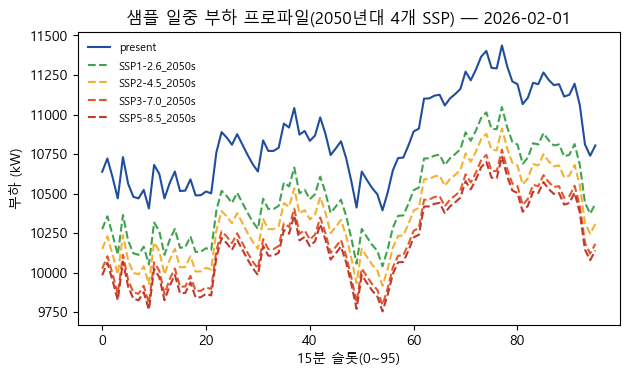

In [2]:
# 1. 미래 부하 생성: data.csv 실측 일중 비중(shape) x 시나리오별 일별 총량 -> 15분 부하(kW)
d15["slot"] = d15.groupby("date").cumcount()                          # 0~95
daily_total_actual = d15.groupby("date")["usage_kwh"].transform("sum")
d15["shape"] = d15["usage_kwh"] / daily_total_actual                   # 일중 비중(하루 합=1)

cal = d15[["date"]].drop_duplicates().merge(est, on="date", how="left")   # 해당 364일의 캘린더·기온·특보

daily_kwh_list = []
for scn, dT in SCENARIOS.items():
    sc = cal.copy()
    for c in ["temp_c", "temp_lag1", "temp_lag2"]:
        sc[c] = cal[c] + dT
    kwh = np.exp(res_multi.predict(sc)) * multi_smear
    daily_kwh_list.append(pd.DataFrame({"date": cal["date"], "scenario": scn, "daily_kwh": kwh}))
daily_kwh = pd.concat(daily_kwh_list, ignore_index=True)

load_15min = d15[["date", "time", "slot", "shape"]].merge(daily_kwh, on="date")
load_15min["load_kw"] = load_15min["shape"] * load_15min["daily_kwh"] * 4   # kWh/15min -> kW
load_15min = load_15min[["date", "time", "slot", "scenario", "load_kw"]]

annual_load = (load_15min.groupby("scenario")["load_kw"].sum().div(4).div(1000)
               .reindex(SCENARIOS.keys()).rename("MWh/year").to_frame())
annual_load["present 대비(%)"] = (annual_load["MWh/year"] / annual_load.loc["present", "MWh/year"] - 1) * 100
print(f"생성 결과: {load_15min['date'].nunique()}일 x 96구간 x {len(SCENARIOS)}시나리오 = {len(load_15min):,}행")
display(annual_load.style.format({"MWh/year": "{:,.0f}", "present 대비(%)": "{:+.2f}%"}))

sample_day = load_15min["date"].drop_duplicates().iloc[150]
show_scn = ["present", "SSP1-2.6_2050s", "SSP2-4.5_2050s", "SSP3-7.0_2050s", "SSP5-8.5_2050s"]
colors = {"present": "#1f4e9c", "SSP1-2.6_2050s": "#3fa34d", "SSP2-4.5_2050s": "#f2b134",
          "SSP3-7.0_2050s": "#e4572e", "SSP5-8.5_2050s": "#c0392b"}
fig, ax = plt.subplots(figsize=(7, 3.8))
sub = load_15min[load_15min["date"] == sample_day]
for scn in show_scn:
    s = sub[sub["scenario"] == scn]
    ax.plot(s["slot"], s["load_kw"], label=scn, color=colors[scn], ls="-" if scn == "present" else "--")
ax.set_xlabel("15분 슬롯(0~95)")
ax.set_ylabel("부하 (kW)")
ax.set_title(f"샘플 일중 부하 프로파일(2050년대 4개 SSP) — {pd.Timestamp(sample_day).date()}")
ax.legend(frameon=False, fontsize=8)
plt.show()

## 2. PV 발전량 계산

`reference/parameters.md`의 PV 출력식 그대로:

$$P_{DC,t}=C_{PV}\frac{G_t}{G_{STC}}\left[1+\gamma(T_{cell,t}-T_{STC})\right]\eta_{sys}$$

- $C_{PV}$=640kW(40기×16kW, Furukakoi 2025), $G_{STC}$=1000W/m², $T_{STC}$=25℃,
  $\gamma$=-0.45%/℃(문서 -0.4~-0.5%/℃ 중간값)
- $G_t$는 `data.csv`의 15분 누적 일사량(MJ/m²)을 평균 W/m²로 환산(×10⁶/900초) — **일사량은
  모든 시나리오에서 실측값 그대로 유지**(SSP는 기온만 이동하는 delta-shift이므로)
- $T_{cell,t}$는 문서에 산출식이 없어 업계 표준 NOCT 근사식으로 추정: $T_{cell}=T_{amb}+\frac{NOCT-20}{800}G_t$
  (NOCT=45℃ 결정질 실리콘 표준값) — **NOCT·$\eta_{sys}$(=0.96)는 parameters.md에 수치가 없어 가정한 값**
- 1절과 동일한 9개 시나리오(present + SSP1-2.6/2-4.5/3-7.0/5-8.5 × 2030s/2050s)에 대해
  $T_{amb}$만 SSP 델타만큼 이동(패널이 더 뜨거워져 발전량이 소폭 감소하는 효과)

PV 설비: 640kW (40기 x 16kW/기, Furukakoi 2025)
설비이용률(present) = 15.5%


,MWh/year,present 대비(%)
scenario,,
present,867,+0.000%
SSP1-2.6_2030s,861,-0.663%
SSP1-2.6_2050s,860,-0.805%
SSP2-4.5_2030s,862,-0.615%
SSP2-4.5_2050s,858,-1.089%
SSP3-7.0_2030s,862,-0.615%
SSP3-7.0_2050s,855,-1.373%
SSP5-8.5_2030s,861,-0.757%
SSP5-8.5_2050s,854,-1.467%


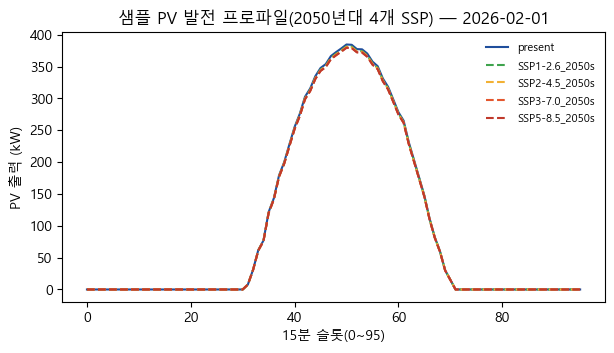

In [3]:
# 2. PV 발전량 계산
C_PV, G_STC, T_STC, NOCT, ETA_SYS = 640.0, 1000.0, 25.0, 45.0, 0.96   # kW, W/m2, C, C, -
GAMMA = -0.0045   # PV 온도계수 (1/C)

G_t_Wm2 = d15["solar_rad_15min_mj_m2"] * 1e6 / 900      # 15분 누적 MJ/m2 -> 평균 W/m2

pv_list = []
for scn, dT in SCENARIOS.items():
    t_amb = d15["temp_c"] + dT
    t_cell = t_amb + (NOCT - 20) / 800 * G_t_Wm2
    pv_kw = (C_PV * (G_t_Wm2 / G_STC) * (1 + GAMMA * (t_cell - T_STC)) * ETA_SYS).clip(lower=0)
    pv_list.append(pd.DataFrame({"date": d15["date"], "time": d15["time"], "slot": d15["slot"],
                                  "scenario": scn, "pv_kw": pv_kw}))
pv = pd.concat(pv_list, ignore_index=True)

annual_pv = (pv.groupby("scenario")["pv_kw"].sum().div(4).div(1000)
             .reindex(SCENARIOS.keys()).rename("MWh/year").to_frame())
annual_pv["present 대비(%)"] = (annual_pv["MWh/year"] / annual_pv.loc["present", "MWh/year"] - 1) * 100
print(f"PV 설비: {C_PV:.0f}kW (40기 x 16kW/기, Furukakoi 2025)")
print(f"설비이용률(present) = {annual_pv.loc['present', 'MWh/year']*1000 / (C_PV*8760):.1%}")
display(annual_pv.style.format({"MWh/year": "{:,.0f}", "present 대비(%)": "{:+.3f}%"}))

fig, ax = plt.subplots(figsize=(7, 3.5))
sub = pv[pv["date"] == sample_day]
for scn in show_scn:
    s = sub[sub["scenario"] == scn]
    ax.plot(s["slot"], s["pv_kw"], label=scn, color=colors[scn], ls="-" if scn == "present" else "--")
ax.set_xlabel("15분 슬롯(0~95)")
ax.set_ylabel("PV 출력 (kW)")
ax.set_title(f"샘플 PV 발전 프로파일(2050년대 4개 SSP) — {pd.Timestamp(sample_day).date()}")
ax.legend(frameon=False, fontsize=8)
plt.show()

## 3. ESS 모델링

아직 최적화는 하지 않고, 4단계 이후에 쓸 **물리적 제약 파라미터**만 정의한다. 이 파라미터는
기후/SSP 시나리오와 무관한 설비 사양이므로 1·2단계처럼 9개로 나누지 않는다.

- $C_{ESS}$=428kWh (캠퍼스 배터리 용량, Furukakoi 2025)
- $C_{PCS}$ = $C_{ESS}$/3h ≈ 142.7kW — parameters.md 경제성 각주의 "3시간 방전 시스템 기준"에서 역산
- $\eta_{ch}=\eta_{dis}=\sqrt{0.83}$ — Li-ion 왕복효율 80~86%(Elalfy 2024)의 중간값(83%)을
  충/방전 각각에 절반씩 배분
- $SOC_{min}$=20%, $SOC_{max}$=90% — parameters.md 제약식 설명("일반적으로 최소 20%, 최대 90%")
- $SOC_0$=50% — 문서에 수치 없어 중간값으로 가정
- $\Delta t$=0.25h(15분) — 1단계 부하 해상도와 일치

In [4]:
# 3. ESS 모델링 (파라미터 정의만, 최적화는 4단계 이후)
C_ESS = 428.0                               # kWh, Furukakoi 2025
C_PCS = C_ESS / 3                           # kW, "3시간 방전 시스템" 기준 역산
ROUND_TRIP_EFF = 0.83                       # Li-ion efficiency 80~86% 중간값, Elalfy 2024
ETA_CH = ETA_DIS = ROUND_TRIP_EFF ** 0.5    # 왕복효율을 충/방전에 절반씩 배분
SOC_MIN, SOC_MAX, SOC_INIT = 0.20, 0.90, 0.50
DT_H = 0.25                                 # 15분

ESS_PARAMS = {
    "C_ESS_kWh": C_ESS, "C_PCS_kW": round(C_PCS, 1),
    "eta_ch": round(ETA_CH, 4), "eta_dis": round(ETA_DIS, 4),
    "SOC_min": SOC_MIN, "SOC_max": SOC_MAX, "SOC_init": SOC_INIT, "dt_h": DT_H,
}
pd.Series(ESS_PARAMS, name="값").to_frame()

,값
C_ESS_kWh,428.00
C_PCS_kW,142.70
eta_ch,0.91
eta_dis,0.91
SOC_min,0.20
SOC_max,0.90
SOC_init,0.50
dt_h,0.25


---
**1~3단계 완료.** 이번 노트북에서 만든 결과물:
`load_15min`(날짜x96구간x9시나리오 긴 형식, present/SSP1-2.6·2-4.5·3-7.0·5-8.5×2030s·2050s
부하 kW), `pv`(동일 9시나리오 PV 출력 kW), `ESS_PARAMS`(배터리 물리 제약, 시나리오 무관).
부하 모델은 `temperature_scenario_analysis.ipynb` 10절의 다중재해모형(res_multi)을 그대로
재사용해 기온 외에 폭염특보·열대야·대설주의보까지 반영했다. 4단계(최적화 문제 정의)부터는
이 세 변수를 그대로 입력으로 받아서 이어가면 된다.